In [23]:
import argparse
import json
import math
import os
import random
from dataclasses import dataclass, field

import nibabel as nib
import numpy as np
import torch
import torch.nn.functional as F

import cornucopia as cc
# `Uniform(a, b)` is a cornucopia "sampler": every time a transform needs a
# random value it calls the sampler, e.g. Uniform(0, 1)() -> 0.37, and
# Uniform(0, 1)(3) -> [0.12, 0.88, 0.45] (one value per tissue).
from cornucopia.random import Uniform
# Low-level resampling helpers (wrap torch.nn.functional.grid_sample).
from cornucopia.utils import warps


import sys
sys.path.append("/home/agustin/phd/synthesis/utils")

import util_freesurfer_segmentation as ufs
import matplotlib.pyplot as plt

from scipy.ndimage import gaussian_filter


In [24]:
seg_fpath = "/home/agustin/phd/synthseg_nextbrain/project/dev/wp3/augmentation/pipeline/data/inputs/seg.nii.gz"
seg = nib.load(seg_fpath).get_fdata()

seg = ufs.merge_seg96_to_seg3(seg) #map to 0,1,2,3
middle_slice = seg.shape[2] // 2

In [25]:
# def gaussian_kernel1d(sigma, ksize):
#     x = torch.arange(ksize) - ksize // 2
#     k = torch.exp(-x.float()**2 / (2 * sigma**2))
#     return k / k.sum()
    
# def gaussian_blur_3d(vol, sigma=1.0, ksize=5):
#     # vol: (C, H, W, D)
#     C = vol.shape[0]
#     k = gaussian_kernel1d(sigma, ksize)
#     x = vol.unsqueeze(0)  # (1, C, H, W, D)
#     pad = ksize // 2
#     # convolución separable en cada eje, groups=C -> cada canal por separado
#     for shape in [(ksize, 1, 1), (1, ksize, 1), (1, 1, ksize)]:
#         w = k.view(1, 1, *shape).repeat(C, 1, 1, 1, 1)
#         padding = tuple(pad if s > 1 else 0 for s in shape)
#         x = F.conv3d(x, w, padding=padding, groups=C)
#     return x.squeeze(0)

Segmentation shape: (197, 233, 189), One-hot shape: torch.Size([4, 197, 233, 189])


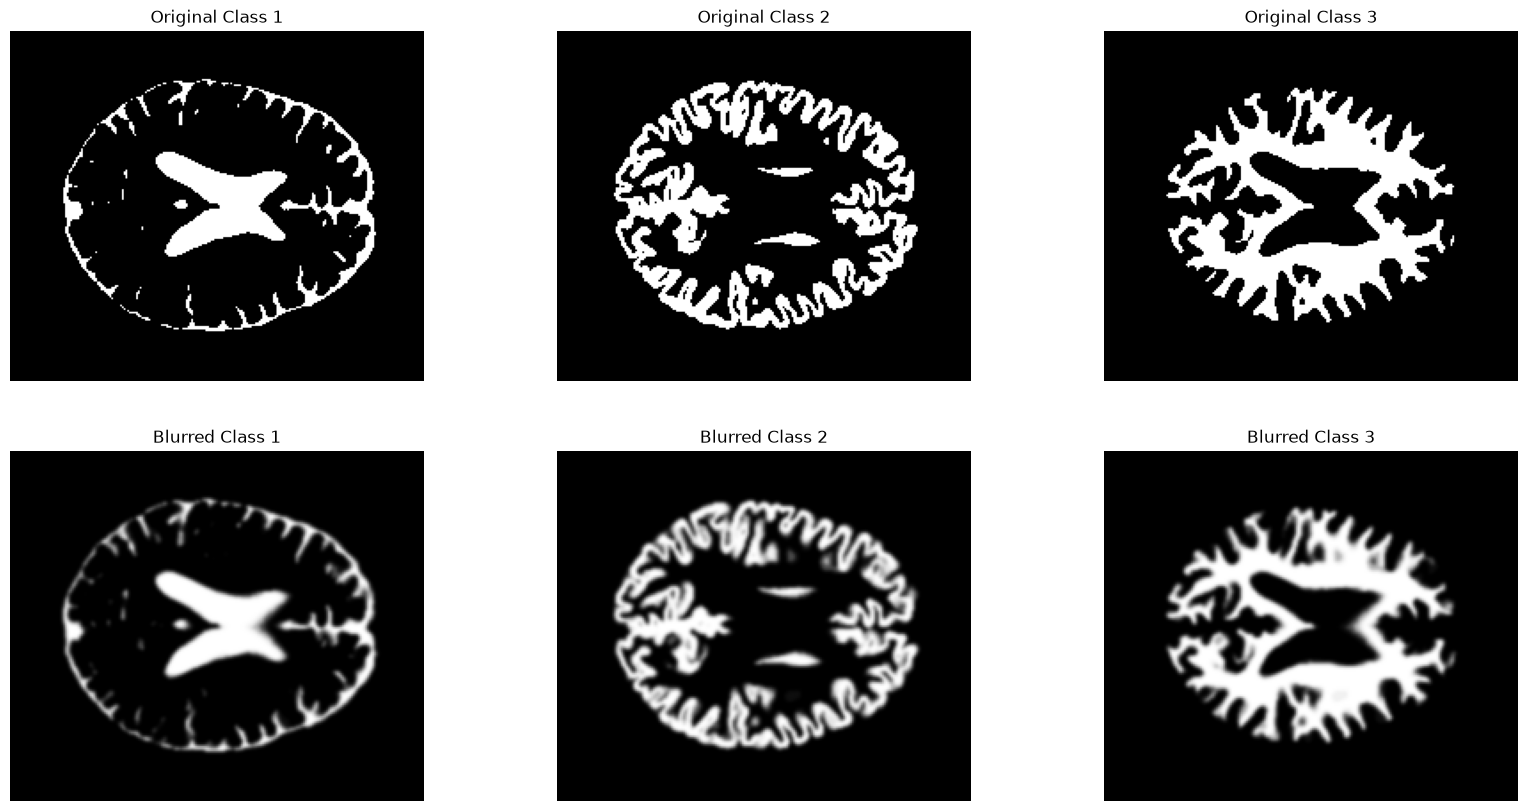

In [26]:
# convert segmentation to one-hot encoding using pytorch
seg_tensor = torch.from_numpy(seg).long()
seg_one_hot = F.one_hot(seg_tensor, num_classes=4).permute(3, 0, 1, 2).float()  # shape: (4, H, W, D)
seg_one_hot_gauss = gaussian_filter(seg_one_hot.numpy(), sigma=(0, 1, 1, 1))
seg_one_hot_gauss = torch.from_numpy(seg_one_hot_gauss)

print(f"Segmentation shape: {seg.shape}, One-hot shape: {seg_one_hot.shape}")
# apply gaussian to each channel of the one-hot encoded segmentation
# seg_one_hot_gaussia = gaussian_blur_3d(seg_one_hot, sigma=1.0, ksize=5)
# show both the original and blurred segmentations for the middle slice
fig, axes = plt.subplots(2, 3, figsize=(20, 10))
for j in range(1, 4):  # skip background class 0
    i = j-1
    axes[0, i].imshow(seg_one_hot[j, :, :, middle_slice], cmap='gray')
    axes[0, i].set_title(f'Original Class {j}')
    axes[0, i].axis('off')

    axes[1, i].imshow(seg_one_hot_gauss[j, :, :, middle_slice], cmap='gray')
    axes[1, i].set_title(f'Blurred Class {j}')
    axes[1, i].axis('off')
plt.show()

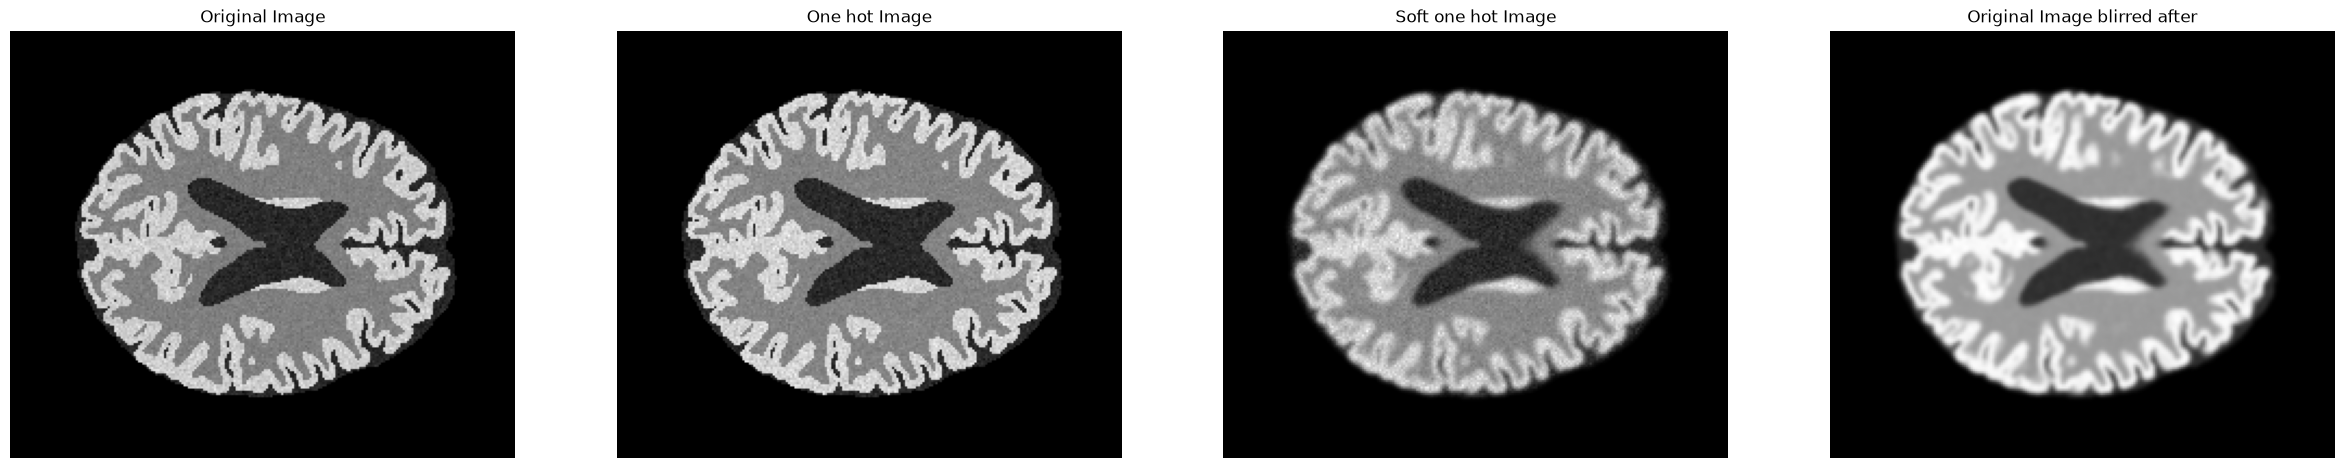

In [36]:
gmm = cc.RandomGaussianMixtureTransform(
    mu=Uniform((0., 1.)),
    sigma=Uniform((0.001, 0.1)),
    fwhm=0,
    background=0
)
gmm = gmm.make_final(seg_one_hot)

img_seg = gmm(seg_tensor[None].clone())  # add batch dimension and convert to float
img_onehot = gmm(seg_one_hot.clone()) 
img_gaussian = gmm(seg_one_hot_gauss.clone())

# apply gaussian bliring to the first one
img_seg_gaussian = gaussian_filter(img_seg.numpy(), sigma=(0, 1, 1, 1))

# img_seg, img_onehot, img_gaussian = gmm(seg_tensor[None]), gmm(seg_one_hot), gmm(seg_one_hot_gauss)
# show the original and blurred images for the middle slice
fig, axes = plt.subplots(1, 4, figsize=(30, 30))
axes[0].imshow(img_seg[0, :, :, middle_slice], cmap='gray')
axes[0].set_title('Original Image')
axes[0].axis('off')
axes[1].imshow(img_onehot[0, :, :, middle_slice], cmap='gray')
axes[1].set_title('One hot Image')
axes[1].axis('off')
axes[2].imshow(img_gaussian[0, :, :, middle_slice], cmap='gray')
axes[2].set_title('Soft one hot Image')
axes[2].axis('off')
axes[3].imshow(img_seg_gaussian[0, :, :, middle_slice], cmap='gray')
axes[3].set_title('Original Image blirred after')
axes[3].axis('off')
plt.show()

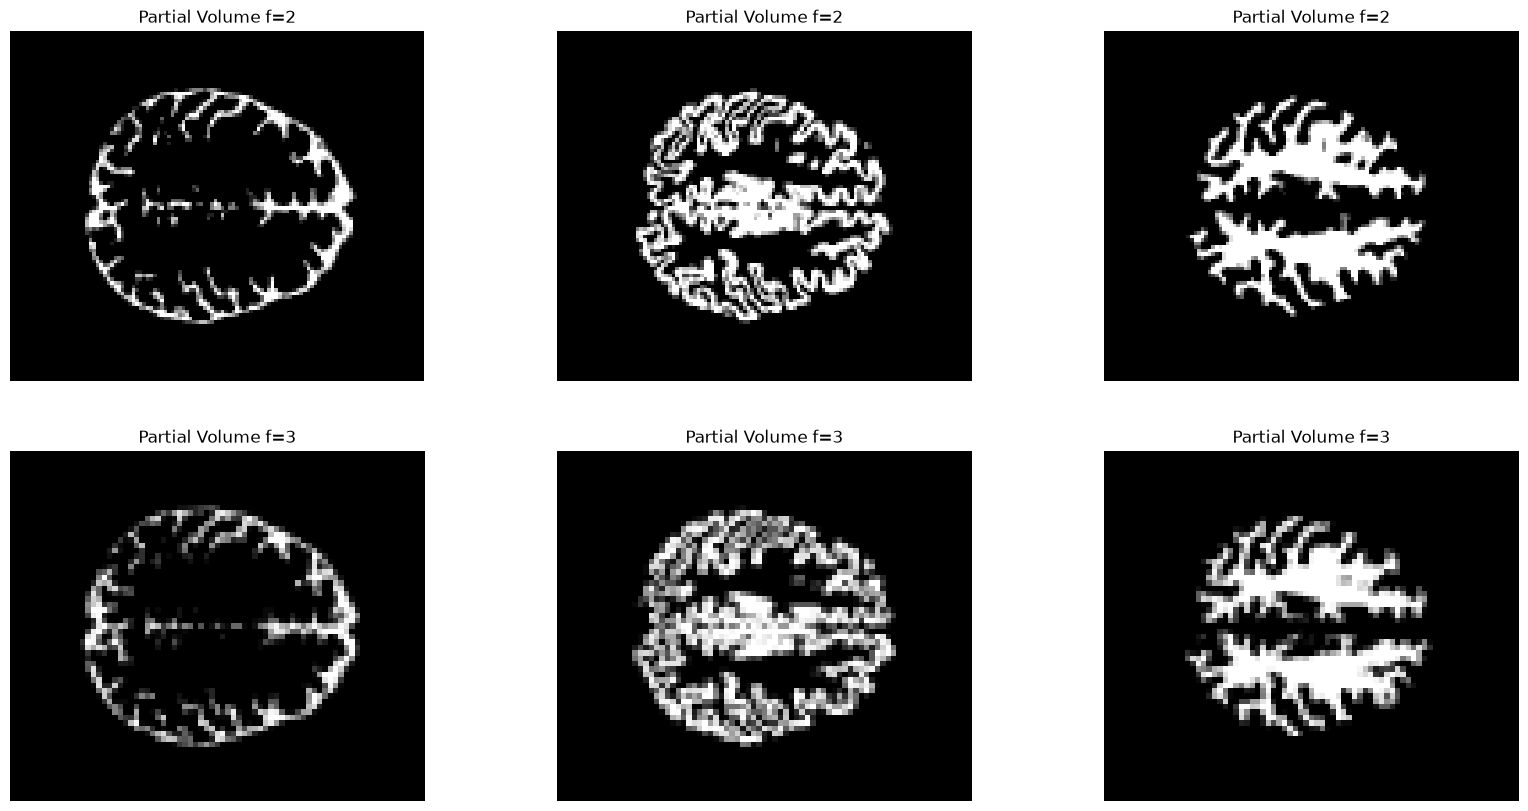

In [55]:
def _partial_volume(lab, f=3, nb_labels=4):
    """
    Average-pool the one-hot HR labels to the training grid.

    Each 0.75 mm voxel contains 3x3x3 = 27 HR voxels. The fraction of
    them belonging to tissue k is its partial-volume (PV) value.

    Example: a voxel on the cortex boundary with 18 GM and 9 WM HR voxels
        pv[gm] = 18/27 = 0.667 ; pv[wm] = 9/27 = 0.333 ; others = 0
    Fractions always sum to 1 at every voxel.

    Returns (K, X/3, Y/3, Z/3) = (14, 240, 296, 260).
    """
    # f = self.cfg.factor
    pv = []
    # One tissue at a time: a full HR one-hot (14 x 499 M floats) would
    # need 28 GB; one channel needs 2 GB.
    # for k in range(self.cfg.nb_labels):
    for k in range(nb_labels):
        m = (lab == k)[None, None].float()       # (1, 1, X, Y, Z) 0./1.
        # avg_pool3d(m, 3): mean over non-overlapping 3x3x3 blocks
        pv.append(F.avg_pool3d(m, f)[0, 0])
        del m
    return torch.stack(pv)



seg_one_hot_pv_1 = _partial_volume(seg_tensor, f=2, nb_labels=4)
seg_one_hot_pv_2 = _partial_volume(seg_tensor, f=3, nb_labels=4)

middle_slice_1  = seg_one_hot_pv_1.shape[2] // 2
middle_slice_2  = seg_one_hot_pv_2.shape[2] // 2
# show the original and partial volume images for the middle slice
fig, axes = plt.subplots(2, 3, figsize=(20, 10))
for j in range(1, 4):  # skip background class 0
    i = j-1
    axes[0, i].imshow(seg_one_hot_pv_1[j, :, :, middle_slice_1], cmap='gray')
    axes[0, i].set_title(f'Partial Volume f=2')
    axes[0, i].axis('off')

    axes[1, i].imshow(seg_one_hot_pv_2[j, :, :, middle_slice_2], cmap='gray')
    axes[1, i].set_title(f'Partial Volume f=3')
    axes[1, i].axis('off')
plt.show()

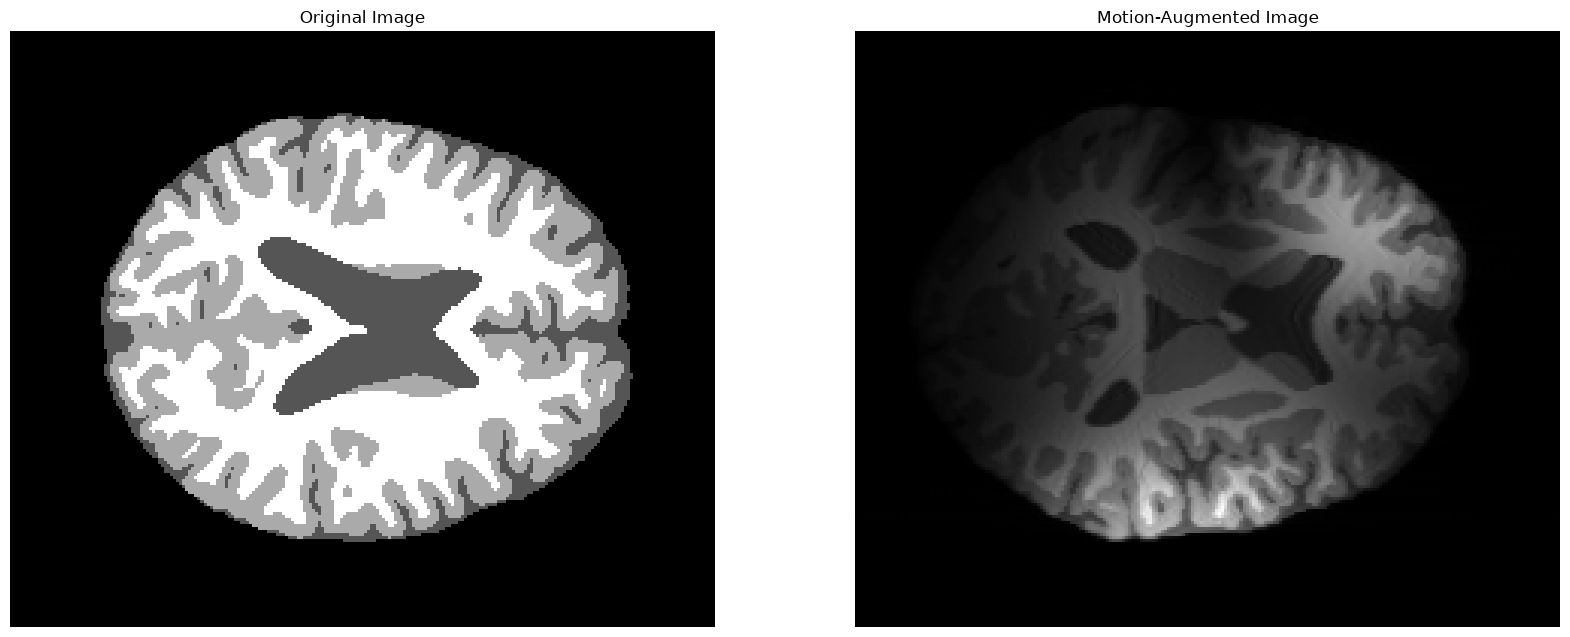

In [ ]:
def _motion(img, motion_prob=0.3, motion_shots=3, motion_translations_mm=10.0, motion_rotations=5.0, target_voxel=0.75):
    """
    Random rigid head motion during the acquisition (k-space model).

    An MRI image is acquired in k-space (Fourier space), line by line.
    If the head moves halfway through, the first part of k-space comes
    from position A and the rest from position B. The reconstructed
    image then shows ghosting / ringing. cornucopia simulates this:
        1. split k-space along `axis` into `shots` contiguous chunks;
        2. for each shot, rigidly move the image (random rotation and
            translation), FFT, and keep only that shot's chunk;
        3. assemble the chunks, inverse FFT, take the magnitude.

    Pattern example: n = 10 k-space lines, 3 shots -> length = 4
        shot 0: lines 0-3   [1 1 1 1 0 0 0 0 0 0]
        shot 1: lines 4-7   [0 0 0 0 1 1 1 1 0 0]
        shot 2: lines 8-9   [0 0 0 0 0 0 0 0 1 1]
    """
    # if random.random() > motion_prob:        # 70% of the time: no-op
    #     return img
    # cornucopia 0.5.1 workarounds for non-cubic volumes:
    # - the motion is sampled for the input shape but applied after
    #   moving `axis` to dim 1 -> we move the axis ourselves, use axis=1;
    # - the (shots, n) pattern broadcasts against the *last* dim -> we
    #   pass a (shots, n, 1, 1) pattern.
    #
    # Random phase-encode axis (1, 2 or 3 = x, y or z; dim 0 is channel).
    # E.g. axis = 2: (1, 240, 296, 260) -> (1, 296, 240, 260)
    axis = random.choice([1, 2, 3])
    img = img.movedim(axis, 1)
    n = img.shape[1]                             # number of k-space lines
    # cornucopia expects translations as a fraction of the FOV:
    #   10 mm / (240 * 0.75 mm = 180 mm) = 0.056
    fov_mm = min(img.shape[1:]) * target_voxel
    # sequential k-space pattern
    length = math.ceil(n / motion_shots)
    pattern = torch.zeros([motion_shots, n, 1, 1], dtype=torch.bool,
                            device=img.device)
    for shot in range(motion_shots):
        pattern[shot, shot * length:(shot + 1) * length] = True

    motion = cc.IntraScanMotionTransform(
        shots=motion_shots,
        axis=1,
        translations=motion_translations_mm / fov_mm,
        rotations=motion_rotations,
        pattern=pattern,
    )

    # it does not works with coils!!!
    # coils=cc.ArrayCoilTransform(ncoils=motion_shots)
    # motion = cc.IntraScanMotionTransform(
    #     shots=motion_shots,
    #     axis=1,
    #     translations=motion_translations_mm / fov_mm,
    #     rotations=motion_rotations,
    #     pattern=pattern,
    #     coils = coils
    # )


    # apply, then put the axis back where it was
    return motion(img).movedim(1, axis)

# print("img_gaussian.shape", img_gaussian.shape)
# print("seg_tensor.shape", seg_tensor.shape)
img_gaussian_motion = _motion(seg_tensor[None].float(), motion_prob=1, motion_shots=3, motion_translations_mm=10.0, motion_rotations=5.0, target_voxel=0.75)
# img_gaussian_motion = _motion(img_gaussian, motion_prob=1, motion_shots=3, motion_translations_mm=10.0, motion_rotations=5.0, target_voxel=0.75)

# show the original and motion-augmented images for the middle slice
fig, axes = plt.subplots(1, 2, figsize=(20, 10))
axes[0].imshow(seg_tensor[ :, :, middle_slice], cmap='gray')
axes[0].set_title('Original Image')
axes[0].axis('off')
axes[1].imshow(img_gaussian_motion[0, :, :, middle_slice], cmap='gray')
axes[1].set_title('Motion-Augmented Image')
axes[1].axis('off')
plt.show()